# Install Requirements

In [1]:
#!pip install -r pip_requirements.txt

# Imports

In [2]:
# --- Jupyter Notebook Utils ---
%matplotlib inline
%load_ext autoreload
%autoreload 2

# --- Python Libraries ---
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math
from datetime import date
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf

# --- Ensure autoreload tracks all your modules ---
import src.utils
import src.models
import src.scripts
import src.data.init_df

# --- Load all symbols (DataFrames, functions, etc.) ---
from src import *

# Data Sanity Check

In [ ]:
check_quality(interactions_df)
check_quality(embeddings_subreddits_df]
check_quality(embeddings_users_df)


=== QUALITY REPORT ===
Shape: (858488, 92)

Missing values:
 SOURCE_SUBREDDIT                          0
LIWC_COGMECH                              0
LIWC_PERCEPT                              0
LIWC_EXCL                                 0
LIWC_INCL                                 0
                                         ..
LIWC_PPRON                                0
LIWC_PRONOUN                              0
LIWC_FUNCT                                0
COMPOUND_SENTIMENT_CALCULATED_BY_VADER    0
TYPE                                      0
Length: 92, dtype: int64

Duplicate rows: 0

=== QUALITY REPORT ===
Shape: (51278, 301)

Missing values:
 SUBREDDIT    0
emb_206      0
emb_204      0
emb_203      0
emb_202      0
            ..
emb_99       0
emb_98       0
emb_97       0
emb_96       0
emb_299      0
Length: 301, dtype: int64

Duplicate rows: 0

=== QUALITY REPORT ===
Shape: (118381, 301)

Missing values:
 USER       0
emb_206    0
emb_204    0
emb_203    0
emb_202    0
          

In [4]:
interactions_df

,SOURCE_SUBREDDIT,TARGET_SUBREDDIT,POST_ID,TIMESTAMP,LINK_SENTIMENT,NUMBER_OF_CHARACTERS,NUMBER_OF_CHARACTERS_WITHOUT_COUNTING_WHITE_SPACE,FRACTION_OF_ALPHABETICAL_CHARACTERS,FRACTION_OF_DIGITS,FRACTION_OF_UPPERCASE_CHARACTERS,...,LIWC_LEISURE,LIWC_HOME,LIWC_MONEY,LIWC_RELIG,LIWC_DEATH,LIWC_ASSENT,LIWC_DISSENT,LIWC_NONFLU,LIWC_FILLER,TYPE
0,agitation,changemyview,1u5cj7s,2013-12-31 16:20:20,1,102.0,91.0,0.843137,0.000000,0.088235,...,0.000000,0.0000,0.0000,0.000000,0.0000,0.000000,0.000000,0.000000,0.000000,title
1,rddtgaming,rddtrust,1u4pzzs,2013-12-31 16:39:18,1,25.0,23.0,0.760000,0.000000,0.440000,...,0.000000,0.0000,0.0000,0.000000,0.0000,0.000000,0.000000,0.000000,0.000000,title
2,leagueoflegends,teamredditteams,1u4nrps,2013-12-31 16:39:58,1,345.0,298.0,0.756522,0.017391,0.086957,...,0.034483,0.0000,0.0000,0.000000,0.0000,0.000000,0.000000,0.000000,0.000000,body
3,examplesofevil,pics,1u5lhas,2013-12-31 16:40:29,1,96.0,83.0,0.833333,0.000000,0.062500,...,0.000000,0.0000,0.0000,0.000000,0.0625,0.000000,0.000000,0.000000,0.000000,title
4,nfl,cfb,1u4sjvs,2013-12-31 17:37:55,1,1124.0,949.0,0.772242,0.001779,0.057829,...,0.020833,0.0000,0.0000,0.000000,0.0000,0.000000,0.000000,0.020833,0.005208,body
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
858483,brasilonreddit,roadcam,68ipe8s,2017-04-30 16:47:50,1,71.0,63.0,0.788732,0.000000,0.112676,...,0.000000,0.0000,0.0000,0.000000,0.0000,0.000000,0.000000,0.000000,0.000000,title
858484,brasilonreddit,bad_cop_no_donut,68ifuvs,2017-04-30 16:47:50,1,194.0,162.0,0.773196,0.000000,0.067010,...,0.000000,0.0000,0.0000,0.000000,0.0000,0.000000,0.000000,0.000000,0.000000,title
858485,mgtow,dataisbeautiful,68ipeos,2017-04-30 16:52:59,1,1129.0,975.0,0.795394,0.015058,0.018601,...,0.016575,0.0000,0.0000,0.000000,0.0000,0.000000,0.005525,0.000000,0.005525,body
858486,mmorpg,blackdesertonline,68ip5os,2017-04-30 16:54:08,1,1100.0,909.0,0.778182,0.001818,0.023636,...,0.034483,0.0000,0.0000,0.014778,0.0000,0.004926,0.000000,0.009852,0.004926,body


---
# Defining core metrics (cyp)

### Provided properties are not enough.



LIWC properties represent the proportion of words in a text that belong to a certain lexicon: $\text{LIWC}_X = \frac{\text{nb words in lexicon } X}{\text{total nb words}}$.

Properties like `LIWC_Anger` or `LIWC_Swear` are thus purely lexical.

The `VADER` score, while being more optimized for social media texts and posts, mainly works like a LIWC score and is practically a lexical repertory of words that are conventionally considered negative or harmful on social platforms.

This cannot be considered an accurate measure of negativity in our study because:

A few examples of caveats thats come with using lexicon-based metrics are: 

- Sarcasm, irony, and context
  - “Stupid guy” in a link targeting a funny video of a guy slipping 
  - “Stupid guy” in a link targeting a video of Trump’s speech  

- Cultural difference in language
  - Some communities are (by culture) founded on “offensive” language without being toxic.
  - For example, a *CallOfDuty* subreddit will frequently mention terms like “grenade” or “headshots.” These words are not toxic in that community, but could be considered so in other subreddits (ones not related to war or gaming).


### Good news: `LINK_SENTIMENT` solves this problem

`LINK_SENTIMENT` is derived using a supervised sentiment classifier trained on manually labeled Reddit data. When labeling, the authors have taken into account their human judgement of context, irony etc. in addition of a purely lexical analysis. So `LINK_SENTIMENT` is designed specifically for inter-subreddit interactions and is our most reliable (categorical) measure for pure negativity.

### But we are interested in toxicity, not just negativity…

Our idea: create a custom toxicity metric that is a weighted average relevant properties (from the 86 provided features).


#### How do we define toxicity?

| Dimension | Description | Example of properties to use |
|------------|--------------|------------------|
| **Emotional intensity** | Measures strength of negative emotion | `Neg_Vader`, `LIWC_Negemo`, `LIWC_Anger`, `LIWC_Anx`... |
| **Aggressive** | Captures hostile or taboo language | `LIWC_Swear`, `LIWC_Sexual`, `LIWC_Death`, `LIWC_Relig`... |
| **Targeting** | Focus on others (potential hostility toward people/groups) | `LIWC_You`, `LIWC_Humans`, `LIWC_Social`... |
| **Not cognitive** | Opposite of reasoned or analytical tone | `LIWC_Insight`, `LIWC_Cause`... |
| **Violent and short** | Style indicators of impulsive or aggressive speech | Number of UPPERCASE words, Readability index, Average word length... |


#### Quantitative check

We want to explore what are the properties that play a determinant role in negativity (which is, as explained above, accurately measured by LINK_SENTIMENT). To do so, we compare the normalized property means between positive and negative links (normalized because some properties have different scales and centers). Look which are the most significantly different for positive VS negative links.


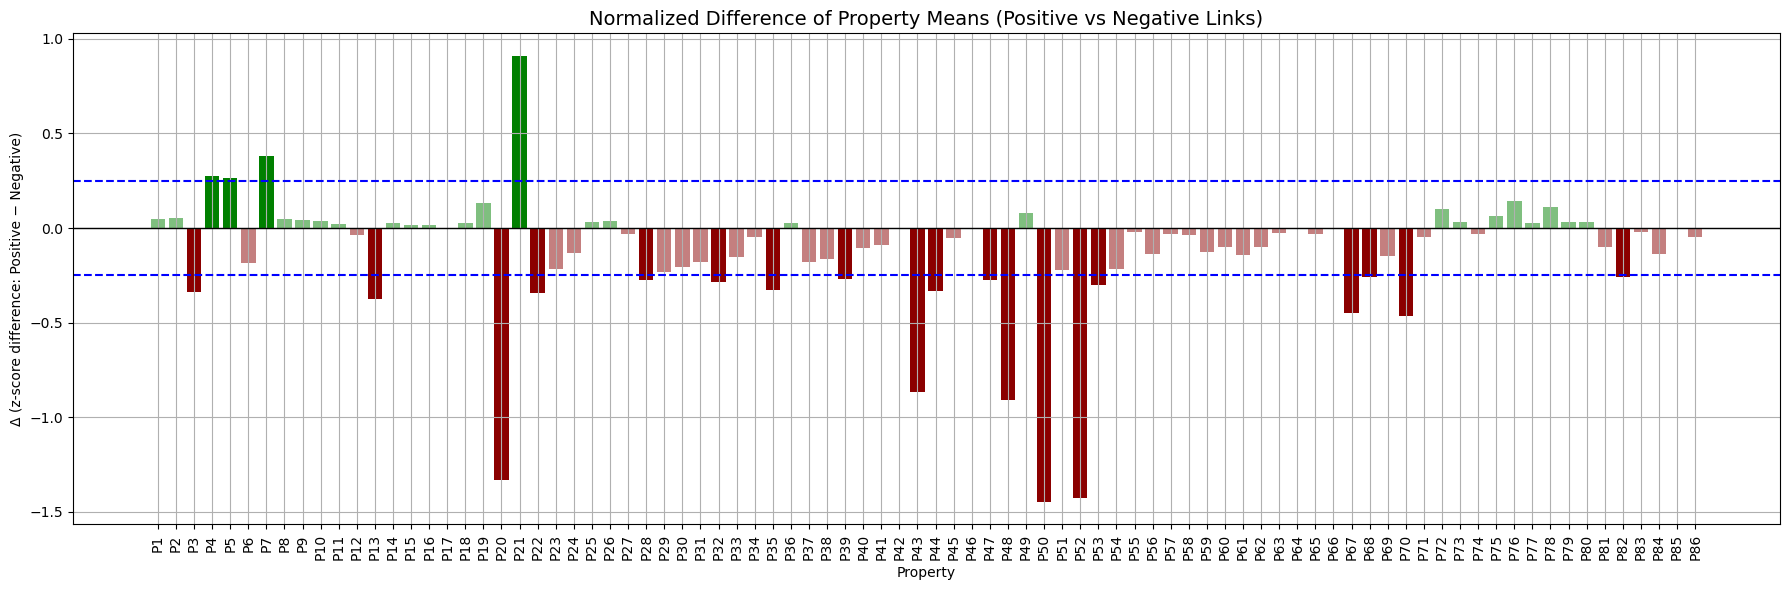

In [274]:
avg_z_diffs = evaluate_props_norm_diffs(interactions_df)

threshold = 0.25

# === Plot ===

plt.figure(figsize=(18, 6))

for i, (prop, diff) in enumerate(avg_z_diffs.items()):
    plt.bar(
        prop,
        diff,
        color = "green" if diff > 0 else "darkred",
        alpha = 1 if abs(diff) > threshold else 0.5
    )
plt.axhline(0, color="black", linewidth=1)
plt.axhline(threshold, color="blue", linestyle = "--")
plt.axhline(-threshold, color="blue", linestyle = "--")
plt.xticks(np.arange(len(avg_z_diffs)), ["P" + str(i + 1) for i in np.arange(len(avg_z_diffs))])
plt.xticks(rotation=90)
plt.title("Normalized Difference of Property Means (Positive vs Negative Links)", fontsize = 14)
plt.ylabel("Δ (z-score difference: Positive − Negative)")
plt.xlabel("Property")
plt.tight_layout()
plt.grid()
plt.show()

In [275]:
high_props = avg_z_diffs[avg_z_diffs > threshold].index.tolist()
low_props = avg_z_diffs[avg_z_diffs < -threshold].index.tolist()

print(f"Found {len(high_props)} properties higher for positive links (zΔ > {threshold}):")
for i in high_props:
    print(f"- (z_diff = {round(avg_z_diffs[i], 3)}) \t {i}")

print(f"\n Found {len(low_props)} Properties higher for negative links (zΔ < -{threshold}):")
for i in low_props:
    print(f"- (z_diff = {round(avg_z_diffs[i], 3)}) \t {i}")

Found 4 properties higher for positive links (zΔ > 0.25):
- (z_diff = 0.273) 	 FRACTION_OF_DIGITS
- (z_diff = 0.262) 	 FRACTION_OF_UPPERCASE_CHARACTERS
- (z_diff = 0.382) 	 FRACTION_OF_SPECIAL_CHARACTERS_SUCH_AS_COMMA_EXCLAMATION_MARK_ETC
- (z_diff = 0.911) 	 COMPOUND_SENTIMENT_CALCULATED_BY_VADER

 Found 19 Properties higher for negative links (zΔ < -0.25):
- (z_diff = -0.34) 	 FRACTION_OF_ALPHABETICAL_CHARACTERS
- (z_diff = -0.375) 	 FRACTION_OF_STOPWORDS
- (z_diff = -1.33) 	 NEGATIVE_SENTIMENT_CALCULATED_BY_VADER
- (z_diff = -0.346) 	 LIWC_FUNCT
- (z_diff = -0.272) 	 LIWC_SHEHE
- (z_diff = -0.287) 	 LIWC_VERBS
- (z_diff = -0.326) 	 LIWC_PRESENT
- (z_diff = -0.27) 	 LIWC_CONJ
- (z_diff = -0.867) 	 LIWC_SWEAR
- (z_diff = -0.33) 	 LIWC_SOCIAL
- (z_diff = -0.273) 	 LIWC_HUMANS
- (z_diff = -0.909) 	 LIWC_AFFECT
- (z_diff = -1.448) 	 LIWC_NEGEMO
- (z_diff = -1.425) 	 LIWC_ANGER
- (z_diff = -0.302) 	 LIWC_SAD
- (z_diff = -0.451) 	 LIWC_BIO
- (z_diff = -0.259) 	 LIWC_BODY
- (z_diff = -0.465

---
Combining our qualitative choice of what defines toxicity with the constraint to mainly use properties that prove to appear in negative hyperlinks only, below is our final choice of the toxicity_metric. Note that all these properties represent ratios (values between 0 and 1) that showed to be significantly lower for positive than for negative links.

Our `toxicity_score` is defined as a weighted average of all these properties and will therefore also be a socre ranging from 0 (not toxic) to 1 (fully toxic).

For now, let’s do an equally weighted average.

In [457]:
interactions_df["LINK_SENTIMENT_ADJUST"] = (1 - (interactions_df["LINK_SENTIMENT"] + 1)/2)/8

tox_props = pd.DataFrame([
    [-5, "FRACTION_OF_DIGITS"],
    [0, "LINK_SENTIMENT_ADJUST"],
    [1, "FRACTION_OF_STOPWORDS"],
    [5, "NEGATIVE_SENTIMENT_CALCULATED_BY_VADER"],
    [-5, "LIWC_CAUSE"],
    [-5, "LIWC_INSIGHT"],
    [5, "LIWC_SWEAR"],
    [1, "LIWC_SOCIAL"],
    [1, "LIWC_HUMANS"],
    [0, "LIWC_AFFECT"],
    [1, "LIWC_NEGEMO"],
    [5, "LIWC_ANGER"],
    [1, "LIWC_SEXUAL"]
    ],
    columns = ["weight", "name"])

# Normalize weights
tox_props["weight (normd)"] = tox_props["weight"] / tox_props["weight"].abs().sum()
display(tox_props)

interactions_df["TOXICITY_SCORE"] = (interactions_df[tox_props["name"].to_list()].values * tox_props["weight (normd)"].to_list()).sum(axis = 1)

,weight,name,weight (normd)
0,-5,FRACTION_OF_DIGITS,-0.142857
1,0,LINK_SENTIMENT_ADJUST,0.000000
2,1,FRACTION_OF_STOPWORDS,0.028571
3,5,NEGATIVE_SENTIMENT_CALCULATED_BY_VADER,0.142857
4,-5,LIWC_CAUSE,-0.142857
5,-5,LIWC_INSIGHT,-0.142857
6,5,LIWC_SWEAR,0.142857
7,1,LIWC_SOCIAL,0.028571
8,1,LIWC_HUMANS,0.028571
9,0,LIWC_AFFECT,0.000000


count    858488.000000
mean          0.014676
std           0.022474
min          -0.121457
25%           0.000785
50%           0.008844
75%           0.021809
max           0.392286
Name: TOXICITY_SCORE, dtype: float64


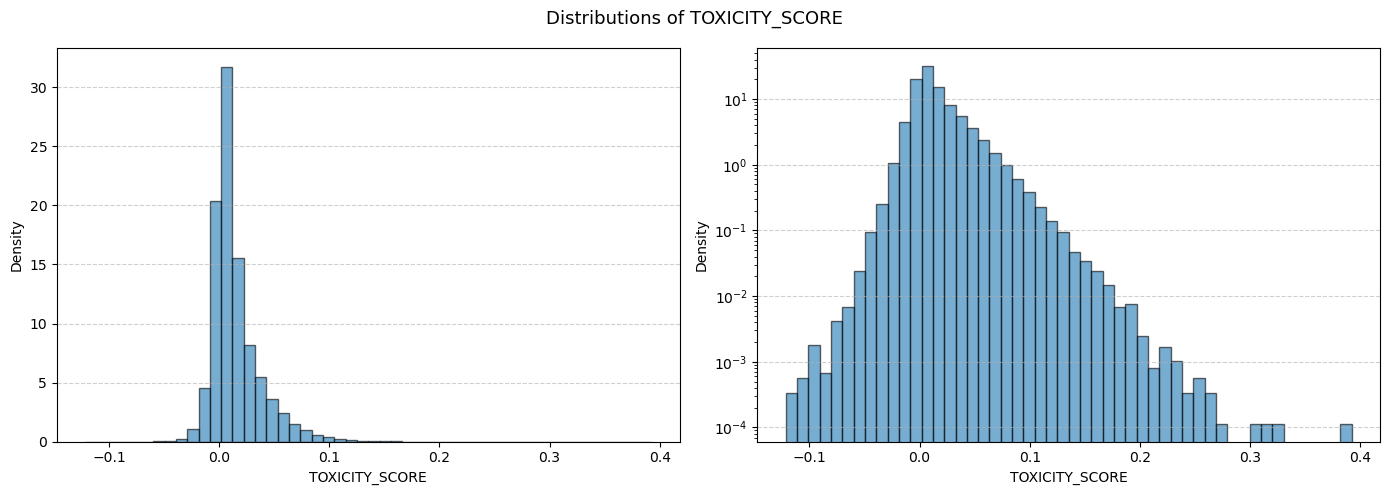

In [458]:
print(interactions_df["TOXICITY_SCORE"].describe())

fig, ax = plt.subplots(1, 2, figsize=(14, 5))  # 1 row, 2 columns

fig.suptitle("Distributions of TOXICITY_SCORE", fontsize=13)

# --- Linear y-axis ---
ax[0].hist(interactions_df["TOXICITY_SCORE"], bins=50, density=True,
           alpha=0.6, edgecolor='black')
ax[0].set_xlabel("TOXICITY_SCORE")
ax[0].set_ylabel("Density")
ax[0].grid(axis='y', linestyle='--', alpha=0.6)

# --- Log y-axis ---
ax[1].hist(interactions_df["TOXICITY_SCORE"], bins=50, density=True,
           alpha=0.6, edgecolor='black')
ax[1].set_xlabel("TOXICITY_SCORE")
ax[1].set_ylabel("Density")
ax[1].set_yscale("log")
ax[1].grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

## Turning it into a CATEGORICAL metric

In [459]:
toxicity_bascule = interactions_df["TOXICITY_SCORE"].quantile(0.75)
print("75% quantile threshold:", toxicity_bascule)

interactions_df["TOXICITY_CAT"] = (interactions_df["TOXICITY_SCORE"] >= toxicity_bascule).astype(int)

75% quantile threshold: 0.02180947633514623


### Will we have enough data?

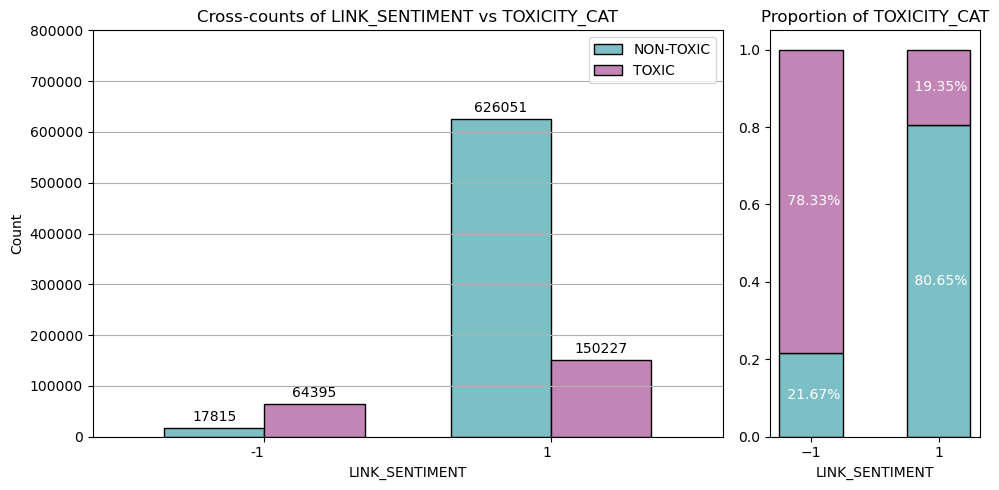

In [460]:
cross_counts = pd.crosstab(interactions_df["LINK_SENTIMENT"], interactions_df["TOXICITY_CAT"])

fig, ax = plt.subplots(1, 2, figsize=(10, 5), gridspec_kw={'width_ratios': [3, 1]})

colors = ["#7CC0C6", "#C185B6"]
cross_counts.plot(
    kind='bar',
    width=0.7,
    color=colors,
    edgecolor='black',
    ax=ax[0]
)

for container in ax[0].containers:
    ax[0].bar_label(container, label_type='edge', fontsize=10, color='black', padding=3)

ax[0].set_xlabel("LINK_SENTIMENT")
ax[0].set_ylabel("Count")
ax[0].set_title("Cross-counts of LINK_SENTIMENT vs TOXICITY_CAT")
ax[0].legend(["NON-TOXIC", "TOXIC"])
ax[0].set_ylim(0, 800000)
ax[0].set_xticklabels([-1, 1], rotation=0, ha='right')
ax[0].grid(axis='y')


negnontox, negtox, posnontox, postox = cross_counts.values.flatten()
n = negnontox + negtox
p = posnontox + postox

nontoxic_percents = [negnontox/n, posnontox/p]
toxic_percents = [negtox/n, postox/p]

# Plot

bars1 = ax[1].bar([-1, 1], nontoxic_percents, color=colors[0], edgecolor = 'black', width = 1)
bars2 = ax[1].bar([-1, 1], toxic_percents, bottom=nontoxic_percents, color=colors[1], edgecolor = 'black', width = 1)

epsilon=1e-6
for bar, value in zip(bars1, nontoxic_percents):
    ax[1].text(bar.get_x() + bar.get_width() / 2, bar.get_height() / 2, f'{value*100: .2f}%', 
            ha='center', va='center', color='white', fontsize=10)

for bar, value, offset in zip(bars2, toxic_percents, nontoxic_percents):
    ax[1].text(bar.get_x() + bar.get_width() / 2, offset + value / 2, f'{value*100: .2f}%', 
            ha='center', va='center', color='white', fontsize=10)

ax[1].set_xticks([-1, 1])
ax[1].set_title("Proportion of TOXICITY_CAT")
ax[1].set_xlabel("LINK_SENTIMENT")
plt.tight_layout()
plt.show()

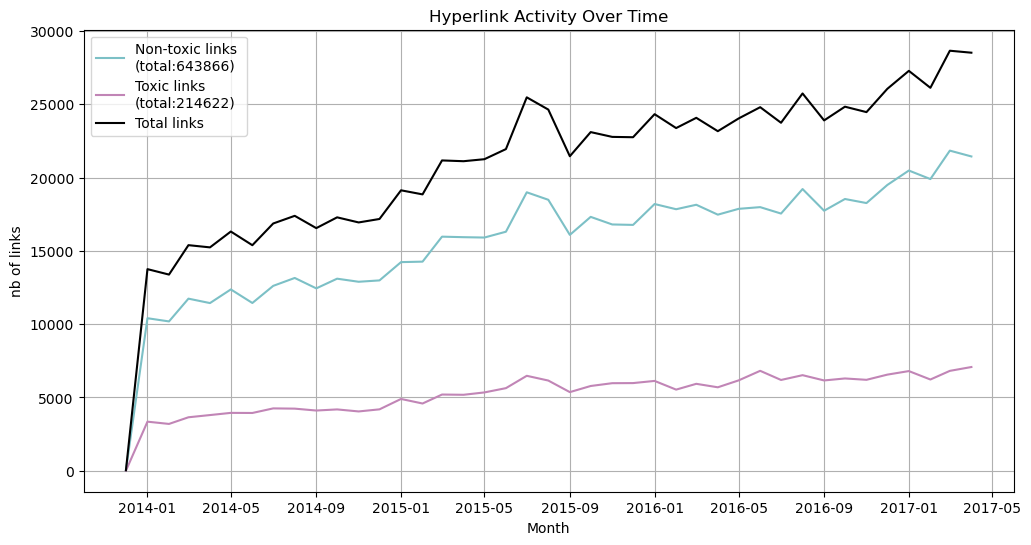

In [461]:
interactions_df["year_month"] = interactions_df["TIMESTAMP"].dt.to_period("M").dt.to_timestamp()

# Count interactions per month and sentiment
links_over_time_sent = (
    interactions_df.groupby(["year_month", "TOXICITY_CAT"])
    .size()
    .reset_index(name="n_links")
)

links_over_time_pivot = links_over_time_sent.pivot(
    index="year_month", columns="TOXICITY_CAT", values="n_links"
).fillna(0)

links_over_time_pivot["total"] = links_over_time_pivot.sum(axis=1)

toxicity_counts = interactions_df["TOXICITY_CAT"].value_counts()

plt.figure(figsize=(12, 6))
plt.plot(links_over_time_pivot.index, links_over_time_pivot[0], label=f"Non-toxic links \n(total:{toxicity_counts[0]})", color=colors[0])
plt.plot(links_over_time_pivot.index, links_over_time_pivot[1], label=f"Toxic links \n(total:{toxicity_counts[1]})", color=colors[1])
plt.plot(links_over_time_pivot.index, links_over_time_pivot["total"], label="Total links", color="black")

plt.title("Hyperlink Activity Over Time")
plt.xlabel("Month")
plt.ylabel("nb of links")
plt.legend()
plt.grid(True)
plt.show()

In [462]:
# Toxicity rolling normalization
rolling_window = "252D"

interactions_df["TOXICITY_SCORE_ROLLZ"] = (
    (interactions_df["TOXICITY_SCORE"] -
     interactions_df.rolling(rolling_window, on="TIMESTAMP")["TOXICITY_SCORE"].mean())
    / interactions_df.rolling(rolling_window, on="TIMESTAMP")["TOXICITY_SCORE"].std()
)


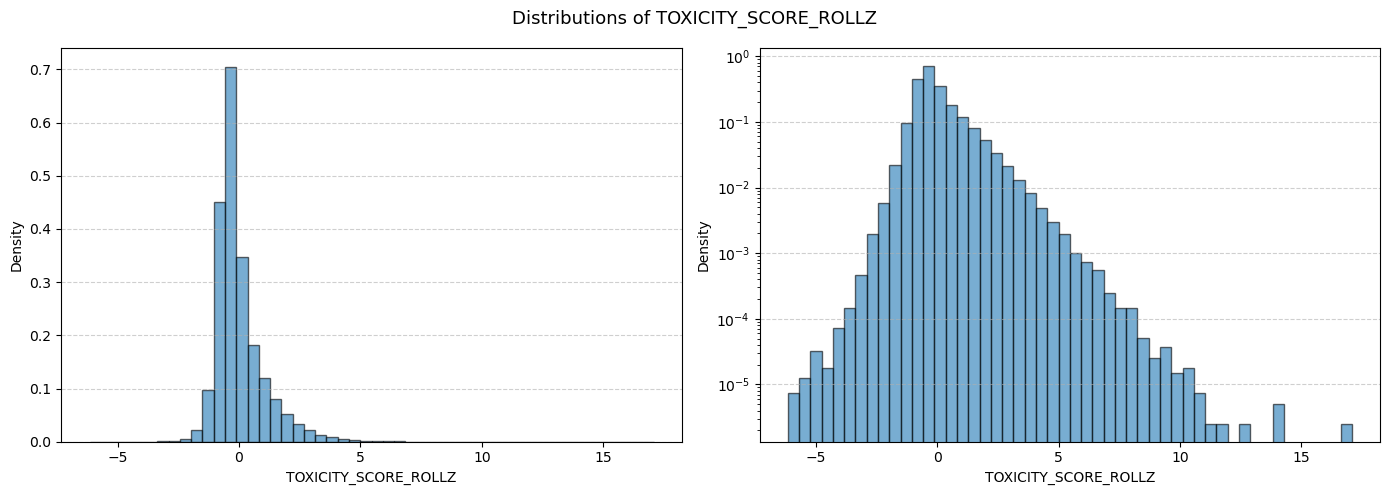

In [463]:
interactions_df["TOXICITY_SCORE_ROLLZ"].describe()

fig, ax = plt.subplots(1, 2, figsize=(14, 5))  # 1 row, 2 columns

fig.suptitle("Distributions of TOXICITY_SCORE_ROLLZ", fontsize=13)

# --- Linear y-axis ---
ax[0].hist(interactions_df["TOXICITY_SCORE_ROLLZ"], bins=50, density=True,
           alpha=0.6, edgecolor='black')
ax[0].set_xlabel("TOXICITY_SCORE_ROLLZ")
ax[0].set_ylabel("Density")
ax[0].grid(axis='y', linestyle='--', alpha=0.6)

# --- Log y-axis ---
ax[1].hist(interactions_df["TOXICITY_SCORE_ROLLZ"], bins=50, density=True,
           alpha=0.6, edgecolor='black')
ax[1].set_xlabel("TOXICITY_SCORE_ROLLZ")
ax[1].set_ylabel("Density")
ax[1].set_yscale("log")
ax[1].grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()